### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


In [4]:
print('Rows, columns:', data.shape)
data.info()

Rows, columns: (12684, 26)
<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null 

2. Investigate the dataset for missing or problematic data.

In [5]:
# Missing values per column (only columns with gaps shown)
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
pd.DataFrame({'missing': missing, 'pct': missing_pct}).query('missing > 0').sort_values('missing', ascending=False)

,missing,pct
car,12576,99.15
CoffeeHouse,217,1.71
Restaurant20To50,189,1.49
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Bar,107,0.84


In [6]:
# Other data-quality checks
print('Duplicate rows:', data.duplicated().sum())
print('Columns with a single value:', [c for c in data.columns if data[c].nunique() == 1])
for col in ['Bar', 'CoffeeHouse', 'age', 'time', 'passanger']:
    print(f'{col}: {sorted(data[col].dropna().unique())}')

Duplicate rows: 74
Columns with a single value: ['toCoupon_GEQ5min']
Bar: ['1~3', '4~8', 'gt8', 'less1', 'never']
CoffeeHouse: ['1~3', '4~8', 'gt8', 'less1', 'never']
age: ['21', '26', '31', '36', '41', '46', '50plus', 'below21']
time: ['10AM', '10PM', '2PM', '6PM', '7AM']
passanger: ['Alone', 'Friend(s)', 'Kid(s)', 'Partner']


**Findings from the data-quality check**

- `car` is missing for **99%** of rows (12,576 of 12,684), so it carries almost no information.
- The five venue-frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) each have a small number of gaps (107–217 rows, under 2%).
- There are **74 exact duplicate rows**.
- `toCoupon_GEQ5min` has the same value (1) in every row, so it cannot distinguish anyone.
- The column `passanger` is misspelled; it is renamed to `passenger` for readability.
- Frequency and age columns are stored as text categories (e.g. `'1~3'`, `'50plus'`), which is fine for grouping but must be handled with care when comparing "more than" / "less than".

3. Decide what to do about your missing data -- drop, replace, other...

In [7]:
df = data.copy()

# 1. Drop the almost-empty and constant columns
df = df.drop(columns=['car', 'toCoupon_GEQ5min'])

# 2. Remove exact duplicate survey responses
df = df.drop_duplicates()

# 3. Fix the column-name typo
df = df.rename(columns={'passanger': 'passenger'})

# 4. Fill the few missing frequency answers with the most common answer (mode) of each column
freq_cols = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
for col in freq_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print('Shape after cleaning:', df.shape)
print('Remaining missing values:', df.isnull().sum().sum())

Shape after cleaning: (12610, 24)
Remaining missing values: 0


**Decision:** `car` and the constant `toCoupon_GEQ5min` were dropped, duplicates removed, and the small number of missing frequency answers (<2% per column) filled with each column's most common value. Imputing with the mode keeps all 12,610 remaining responses while barely changing each column's distribution; dropping those rows instead would have discarded around 5% of the data.

4. What proportion of the total observations chose to accept the coupon?



In [8]:
accept_rate = df['Y'].mean()
print(f'Overall acceptance rate: {accept_rate:.1%}')
df['Y'].value_counts(normalize=True).rename({1: 'Accepted', 0: 'Rejected'})

Overall acceptance rate: 56.8%


Y
Accepted    0.567565
Rejected    0.432435
Name: proportion, dtype: float64

**About 57% of all coupons offered were accepted** (either right away or later). Drivers are slightly more likely to say yes than no overall, but as the next charts show, this varies a lot by coupon type.

5. Use a bar plot to visualize the `coupon` column.

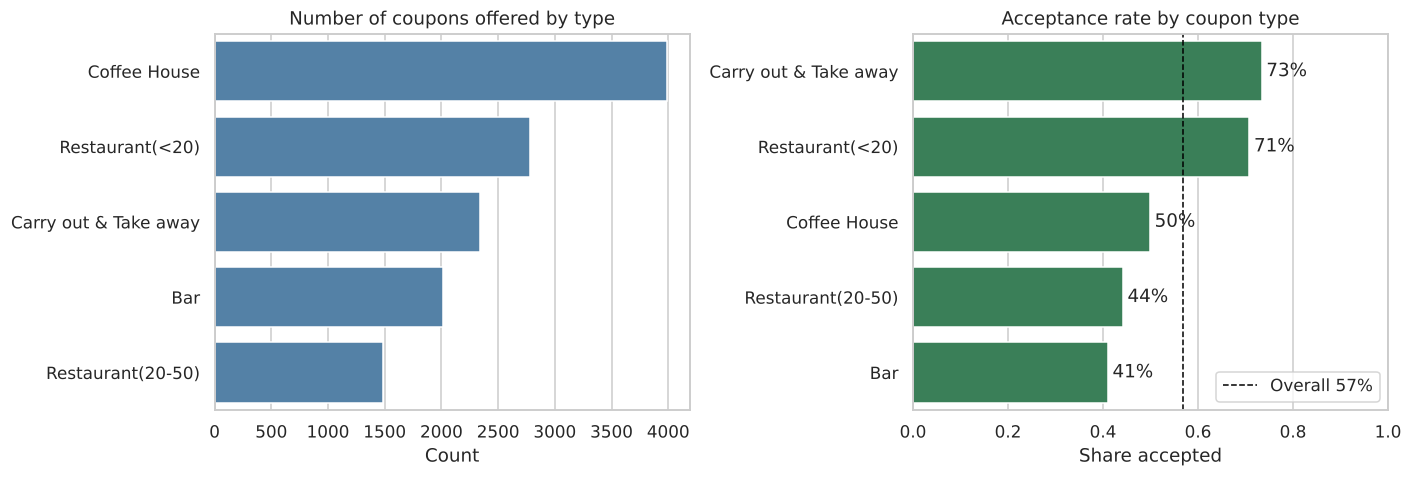

In [9]:
order = df['coupon'].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, y='coupon', order=order, ax=axes[0], color='steelblue')
axes[0].set_title('Number of coupons offered by type')
axes[0].set_xlabel('Count'); axes[0].set_ylabel('')

rate = df.groupby('coupon')['Y'].mean().sort_values(ascending=False)
sns.barplot(x=rate.values, y=rate.index, ax=axes[1], color='seagreen')
axes[1].axvline(accept_rate, color='black', ls='--', lw=1, label=f'Overall {accept_rate:.0%}')
for i, v in enumerate(rate.values):
    axes[1].text(v + 0.01, i, f'{v:.0%}', va='center')
axes[1].set_title('Acceptance rate by coupon type')
axes[1].set_xlabel('Share accepted'); axes[1].set_ylabel(''); axes[1].set_xlim(0, 1)
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/coupon_types.png', bbox_inches='tight')
plt.show()

Coffee House coupons are offered most often, but **cheap restaurants (<\$20) and carry-out coupons are accepted most (71–73%)**, while **bar (41%) and expensive-restaurant (44%) coupons are accepted least.** Low-cost, low-commitment offers convert far better.

6. Use a histogram to visualize the temperature column.

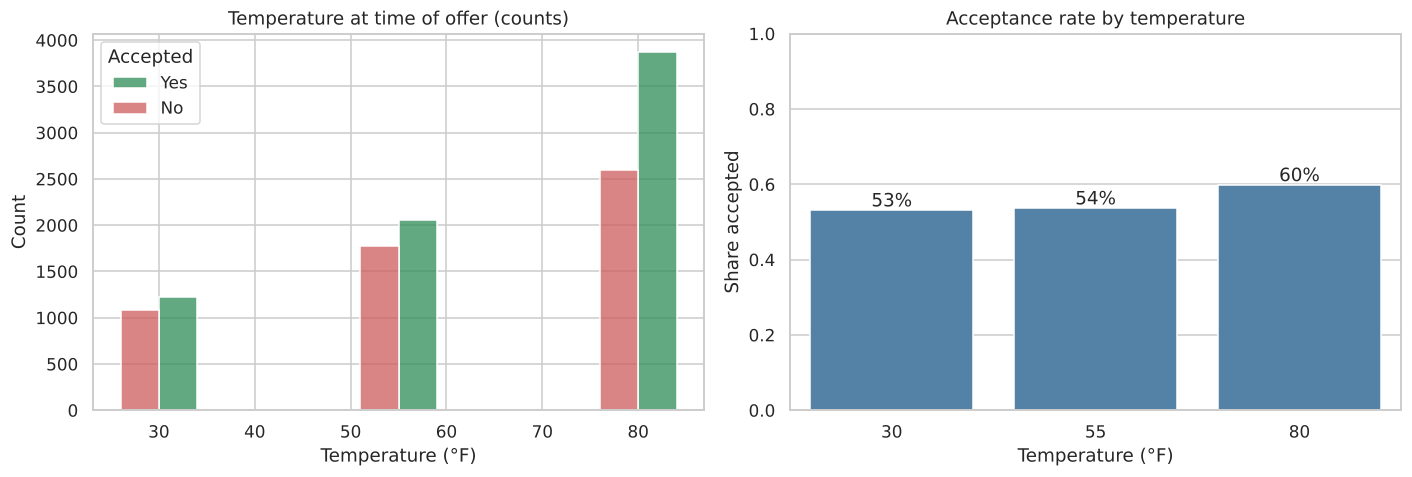

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x='temperature', hue='Y', multiple='dodge', discrete=True, shrink=8,
             ax=axes[0], palette={0: 'indianred', 1: 'seagreen'})
axes[0].set_title('Temperature at time of offer (counts)')
axes[0].set_xlabel('Temperature (°F)')
axes[0].legend(title='Accepted', labels=['Yes', 'No'])

temp_rate = df.groupby('temperature')['Y'].mean()
sns.barplot(x=temp_rate.index, y=temp_rate.values, ax=axes[1], color='steelblue')
for i, v in enumerate(temp_rate.values):
    axes[1].text(i, v + 0.01, f'{v:.0%}', ha='center')
axes[1].set_title('Acceptance rate by temperature')
axes[1].set_xlabel('Temperature (°F)'); axes[1].set_ylabel('Share accepted'); axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.savefig('images/temperature.png', bbox_inches='tight')
plt.show()

The survey only uses three temperatures (30°F, 55°F, 80°F), so the histogram has three bars. Most scenarios are set at 80°F, and **acceptance rises with temperature** — warmer weather makes a detour more appealing.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [11]:
bar = df[df['coupon'] == 'Bar'].copy()
print('Bar coupons:', len(bar))
bar.head()

Bar coupons: 2010


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,never,1~3,4~8,1~3,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,never,1~3,4~8,1~3,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,never,1~3,4~8,1~3,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,never,less1,4~8,4~8,less1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,never,less1,4~8,4~8,less1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


In [12]:
bar_rate = bar['Y'].mean()
print(f'Bar coupon acceptance rate: {bar_rate:.1%}')

Bar coupon acceptance rate: 41.0%


Only **41%** of bar coupons were accepted — well below the 57% overall rate.

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [13]:
# Helper: compare acceptance between a group (mask True) and everyone else
def compare(frame, mask, label_in, label_out):
    r_in, r_out = frame.loc[mask, 'Y'].mean(), frame.loc[~mask, 'Y'].mean()
    print(f'{label_in}: {r_in:.1%}  (n={mask.sum()})')
    print(f'{label_out}: {r_out:.1%}  (n={(~mask).sum()})')
    print(f'Difference: {(r_in - r_out) * 100:+.1f} percentage points')
    return r_in, r_out

three_or_fewer = bar['Bar'].isin(['never', 'less1', '1~3'])
compare(bar, ~three_or_fewer, 'Go to bars more than 3 times/month', 'Go 3 or fewer times/month');

Go to bars more than 3 times/month: 76.9%  (n=199)
Go 3 or fewer times/month: 37.1%  (n=1811)
Difference: +39.8 percentage points


Frequent bar-goers (4+ visits a month) accept bar coupons at **77%**, roughly **double** the 37% rate of those who go 3 or fewer times.

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [14]:
more_than_once = bar['Bar'].isin(['1~3', '4~8', 'gt8'])
over_25 = ~bar['age'].isin(['below21', '21'])   # '21' bucket = ages 21-25
compare(bar, more_than_once & over_25,
        'Bar >1/month AND over 25', 'All others');

Bar >1/month AND over 25: 69.5%  (n=420)
All others: 33.5%  (n=1590)
Difference: +36.1 percentage points


Yes — a large difference: **70% vs 33%**. Regular bar-goers over 25 are more than twice as likely to accept.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [15]:
not_kid = bar['passenger'] != 'Kid(s)'
not_farming = bar['occupation'] != 'Farming Fishing & Forestry'
compare(bar, more_than_once & not_kid & not_farming,
        'Bar >1/month, no kids in car, not farming/fishing/forestry', 'All others');

Bar >1/month, no kids in car, not farming/fishing/forestry: 71.3%  (n=551)
All others: 29.5%  (n=1459)
Difference: +41.8 percentage points


Again a strong gap: **71% vs 30%**. Having children in the car is a clear deterrent for bar coupons.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [16]:
not_widowed = bar['maritalStatus'] != 'Widowed'
under_30 = bar['age'].isin(['below21', '21', '26'])   # '26' bucket = ages 26-30
cheap_rest_4plus = bar['RestaurantLessThan20'].isin(['4~8', 'gt8'])
low_income = bar['income'].isin(['Less than $12500', '$12500 - $24999',
                                  '$25000 - $37499', '$37500 - $49999'])

g1 = more_than_once & not_kid & not_widowed
g2 = more_than_once & under_30
g3 = cheap_rest_4plus & low_income

for name, m in [('Group 1: bar >1/month, no kids, not widowed', g1),
                ('Group 2: bar >1/month, under 30', g2),
                ('Group 3: cheap restaurants 4+/month, income < $50K', g3),
                ('Any of the three groups (OR)', g1 | g2 | g3)]:
    print(name)
    compare(bar, m, '   in group', '   not in group')
    print()

Group 1: bar >1/month, no kids, not widowed
   in group: 71.3%  (n=551)
   not in group: 29.5%  (n=1459)
Difference: +41.8 percentage points

Group 2: bar >1/month, under 30
   in group: 72.2%  (n=345)
   not in group: 34.5%  (n=1665)
Difference: +37.6 percentage points

Group 3: cheap restaurants 4+/month, income < $50K
   in group: 45.3%  (n=344)
   not in group: 40.1%  (n=1666)
Difference: +5.3 percentage points

Any of the three groups (OR)
   in group: 58.9%  (n=776)
   not in group: 29.7%  (n=1234)
Difference: +29.2 percentage points



- Groups 1 and 2 (both built on **going to bars more than once a month**) accept at **71–72%**, versus roughly 30–35% for everyone else.
- Group 3 (frequent cheap-restaurant diners on lower incomes) shows only a small lift (**45% vs 40%**) — income and cheap-dining habits matter much less than bar habits.
- Combining the three with OR gives 59% vs 30%; the lift comes almost entirely from Groups 1 and 2.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

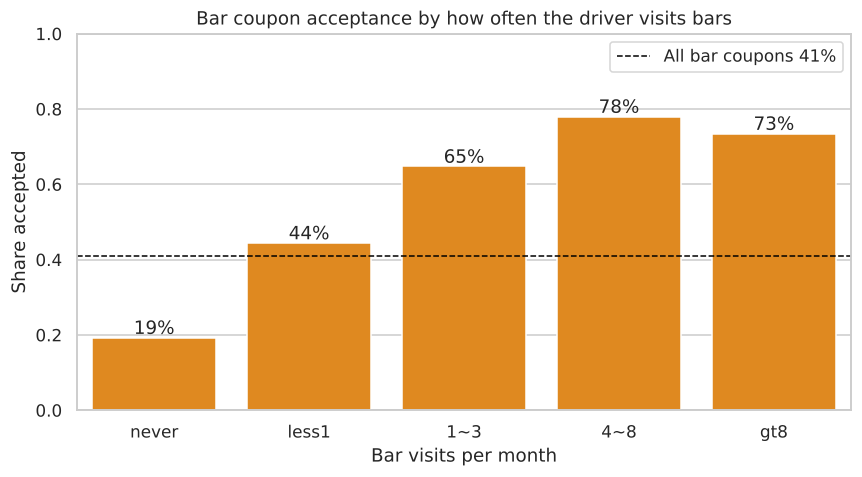

In [17]:
bar_freq_order = ['never', 'less1', '1~3', '4~8', 'gt8']
fig, ax = plt.subplots(figsize=(8, 4.5))
rates = bar.groupby('Bar')['Y'].mean().reindex(bar_freq_order)
sns.barplot(x=rates.index, y=rates.values, color='darkorange', ax=ax)
for i, v in enumerate(rates.values):
    ax.text(i, v + 0.01, f'{v:.0%}', ha='center')
ax.axhline(bar_rate, color='black', ls='--', lw=1, label=f'All bar coupons {bar_rate:.0%}')
ax.set_title('Bar coupon acceptance by how often the driver visits bars')
ax.set_xlabel('Bar visits per month'); ax.set_ylabel('Share accepted'); ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.savefig('images/bar_frequency.png', bbox_inches='tight')
plt.show()

**Hypothesis about drivers who accept bar coupons**

The single strongest driver is **existing bar habit**: acceptance climbs from ~19% for people who never go to bars to 65–78% for those who go at least once a month. Within that group, acceptance is highest for drivers who are **younger (under 30)** and **do not have children in the car**. Income and cheap-restaurant habits add little.

In other words, bar coupons work as a *reminder for existing customers*, not as a way to *create new bar-goers*. Targeting should be restricted to regular bar visitors, adults travelling without kids.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

I chose **Coffee House coupons**: they are the most frequently offered coupon (about 4,000 offers, ~32% of all), and they sit right at the 50% acceptance mark, so understanding who says yes has the biggest commercial upside.

In [18]:
coffee = df[df['coupon'] == 'Coffee House'].copy()
coffee_rate = coffee['Y'].mean()
print('Coffee House coupons:', len(coffee))
print(f'Coffee House acceptance rate: {coffee_rate:.1%}')

Coffee House coupons: 3989
Coffee House acceptance rate: 49.9%


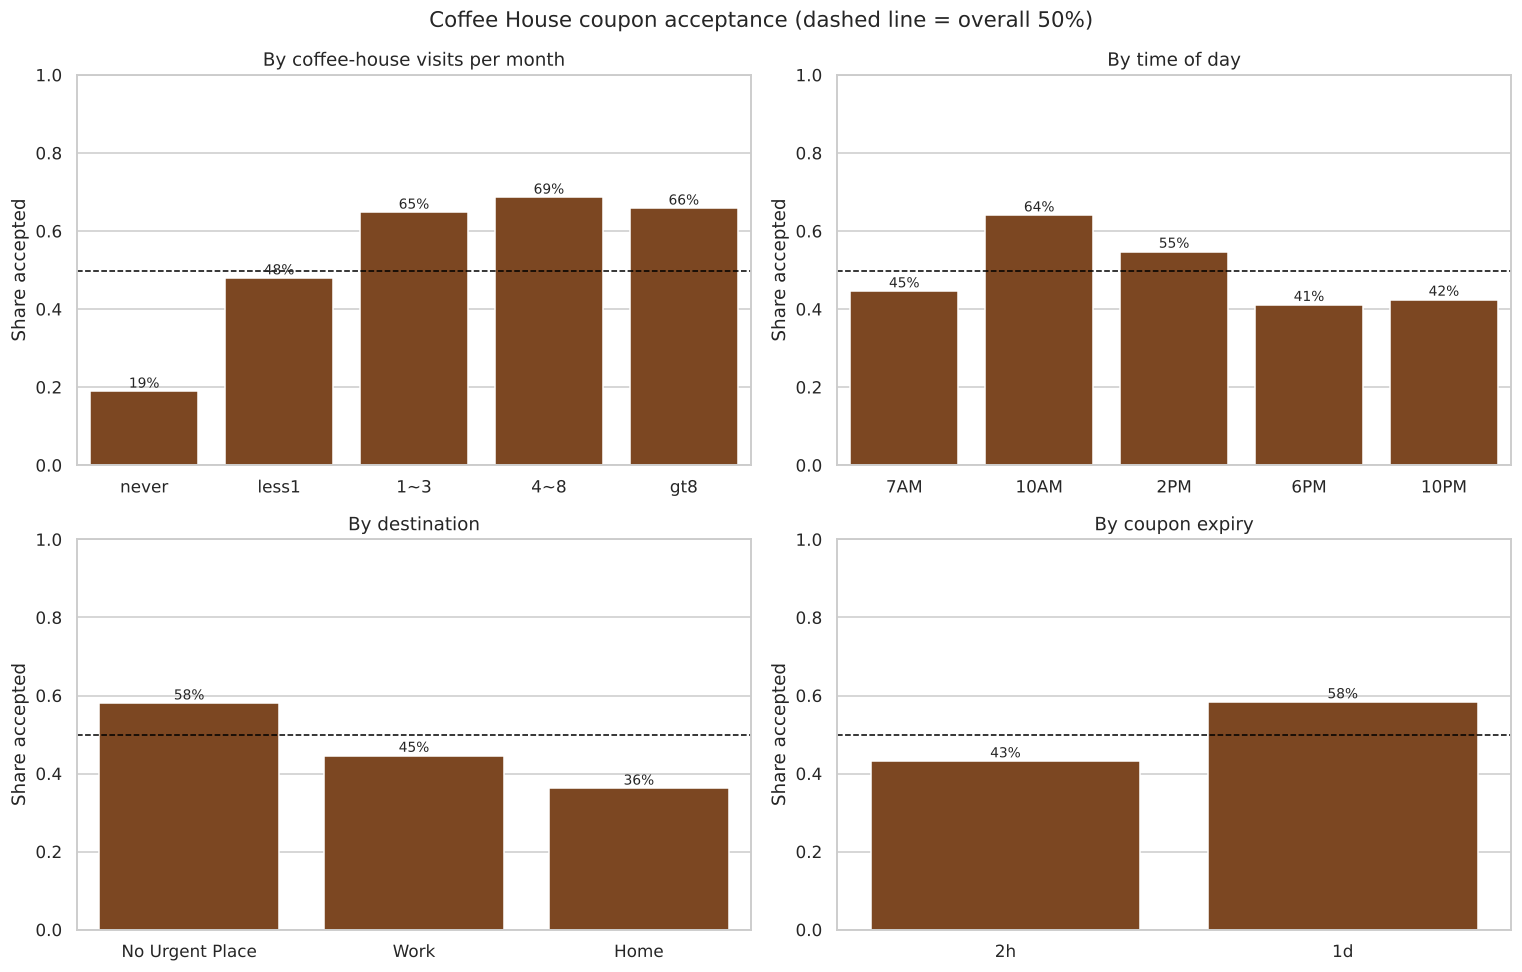

In [19]:
# Acceptance rate for each value of the most relevant features
def rate_plot(frame, col, order, ax, title, color='saddlebrown'):
    r = frame.groupby(col)['Y'].mean().reindex(order)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color=color)
    for i, v in enumerate(r.values):
        ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=9)
    ax.axhline(frame['Y'].mean(), color='black', ls='--', lw=1)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('Share accepted'); ax.set_ylim(0, 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
rate_plot(coffee, 'CoffeeHouse', ['never', 'less1', '1~3', '4~8', 'gt8'], axes[0, 0], 'By coffee-house visits per month')
rate_plot(coffee, 'time', ['7AM', '10AM', '2PM', '6PM', '10PM'], axes[0, 1], 'By time of day')
rate_plot(coffee, 'destination', ['No Urgent Place', 'Work', 'Home'], axes[1, 0], 'By destination')
rate_plot(coffee, 'expiration', ['2h', '1d'], axes[1, 1], 'By coupon expiry')
fig.suptitle('Coffee House coupon acceptance (dashed line = overall 50%)', fontsize=14)
plt.tight_layout()
plt.savefig('images/coffee_drivers.png', bbox_inches='tight')
plt.show()

**What stands out**

- **Habit dominates again.** Drivers who never visit coffee houses accept only **19%** of offers; anyone visiting at least once a month accepts **65–69%**.
- **Time of day:** acceptance peaks mid-morning (**64% at 10 AM**) and drops in the evening (41–42% at 6 PM and 10 PM). Surprisingly, the 7 AM commute is weak (45%) — people heading to work are in a hurry.
- **Destination:** drivers with **no urgent destination** accept 58%; those heading home accept only 36%.
- **Expiry:** a 1-day coupon is accepted 58% of the time vs 43% for a 2-hour coupon — people like the option to use it later.

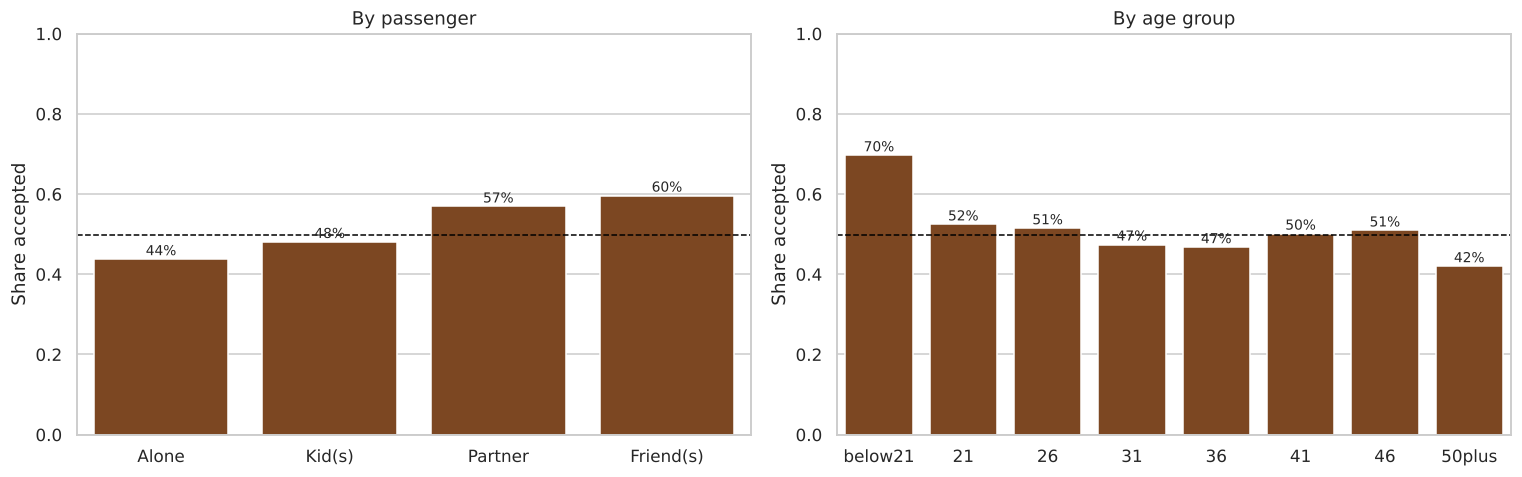

Acceptance when the venue is 25+ minutes away: 35%
Acceptance when it is closer: 51%


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rate_plot(coffee, 'passenger', ['Alone', 'Kid(s)', 'Partner', 'Friend(s)'], axes[0], 'By passenger')
rate_plot(coffee, 'age', ['below21', '21', '26', '31', '36', '41', '46', '50plus'], axes[1], 'By age group')
plt.tight_layout()
plt.savefig('images/coffee_passenger_age.png', bbox_inches='tight')
plt.show()

# Distance to the coffee house
print('Acceptance when the venue is 25+ minutes away:', f"{coffee.loc[coffee['toCoupon_GEQ25min'] == 1, 'Y'].mean():.0%}")
print('Acceptance when it is closer:', f"{coffee.loc[coffee['toCoupon_GEQ25min'] == 0, 'Y'].mean():.0%}")

- Driving **with friends or a partner** raises acceptance (57–60%) compared with driving alone (44%) — coffee is a social stop.
- **Under-21s** are the most receptive age group (70%); acceptance is fairly flat across other ages, dipping for 50+.
- Distance matters: if the coffee house is 25+ minutes away, acceptance falls to about a third.

In [21]:
# Combine the strongest signals into one target segment
regular = coffee['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
no_rush = coffee['destination'] == 'No Urgent Place'
daytime = coffee['time'].isin(['10AM', '2PM'])

segments = {
    'All Coffee House offers': pd.Series(True, index=coffee.index),
    'Regular coffee drinkers (1+ visit/month)': regular,
    'Regular + no urgent destination': regular & no_rush,
    'Regular + no urgent destination + 10AM/2PM': regular & no_rush & daytime,
    'Never visits coffee houses': coffee['CoffeeHouse'] == 'never',
}
summary = pd.DataFrame({name: {'acceptance': coffee.loc[m, 'Y'].mean(), 'offers': int(m.sum())}
                        for name, m in segments.items()}).T
summary['acceptance'] = summary['acceptance'].map('{:.0%}'.format)
summary

,acceptance,offers
All Coffee House offers,50%,3989.0
Regular coffee drinkers (1+ visit/month),66%,1918.0
Regular + no urgent destination,74%,1036.0
Regular + no urgent destination + 10AM/2PM,77%,810.0
Never visits coffee houses,19%,927.0


**Hypothesis about drivers who accept Coffee House coupons**

The ideal Coffee House target is a **regular coffee drinker, on a non-urgent trip, during the day**: this segment accepts **77%** of offers — versus 50% for all offers and only 19% for people who never visit coffee houses. Offering a 1-day expiry and targeting drivers travelling with company lifts acceptance further.

---
## Findings

1. **Overall, 57% of coupons are accepted**, but acceptance depends heavily on the coupon type: cheap restaurants (71%) and carry-out (73%) convert well; bars (41%) and expensive restaurants (44%) convert poorly.
2. **Existing habit is the strongest predictor of acceptance.** For both bars and coffee houses, people who already visit the venue at least once a month accept roughly 2–3× as often as people who never go.
3. **Context matters.** Acceptance is higher in warm weather, mid-morning and early afternoon, on non-urgent trips, when travelling with friends or a partner, and when the venue is close. It is lower on the way home, at night, and when the venue is 25+ minutes away.
4. **Children in the car suppress bar-coupon acceptance**; younger drivers (under 30) are the most receptive to bar coupons.
5. **Longer-dated coupons (1 day) beat short ones (2 hours)** for coffee houses — drivers value the flexibility to use the coupon later.

## Actionable recommendations for Amazon

- **Target by habit, not just location.** Send bar and coffee coupons primarily to drivers who already visit those venues at least monthly; avoid sending them to people who never go (acceptance under 20%).
- **Prioritise low-cost, low-commitment offers** (cheap restaurants, carry-out, coffee) — these deliver the best return on each coupon pushed.
- **Time the offers:** focus coffee coupons on 10 AM–2 PM and on non-urgent trips; reduce pushes during the morning commute and late evening.
- **Use 1-day expiry by default** for coffee coupons, as it measurably increases acceptance.
- **Suppress bar coupons when children are in the car**, and keep distance thresholds tight (under 25 minutes).
- **Next step:** build a classification model (e.g. logistic regression or decision tree, covered later in the program) on these features to score each driver–coupon pair in real time.

**Verdict:** the idea is a good one **if targeted** — blanket coupon delivery would waste many offers, but a habit- and context-aware targeting rule can lift acceptance from ~50% to 70–77% in the best segments.